# Play Tic-Tac-Toe Interactively (Simple Implementation)

Run the notebook cells in order. The X and O game cells are opt-in so that Run All does not block; set the corresponding `PLAY_AS_X` or `PLAY_AS_O` flag to `True` and run that cell to play. Enter `-1` to end a game cleanly.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, check_board, show_board
from tictactoe import random_player, play 

## Implement an Interactive Game


### Interactive Player

Implement the interactive player. It shows the board and asks you for the move.

In [3]:
from IPython.display import clear_output

class GameAborted(Exception):
    pass

def interactive_player(board, player=None):
    if terminal(board):
        raise ValueError("cannot request a move from a terminal board")

    clear_output(wait=False)
    show_board(board, help=True)

    available = actions(board)
    print(f"Available actions are: {available}")

    while True:
        try:
            move = int(input("Your move (0-8 or -1 to end the game):\n"))
        except ValueError:
            print("Please enter an integer move.")
            continue

        if move == -1:
            raise GameAborted
        if move in available:
            return move
        print("Please enter a valid move.")

def play_interactively(human_side):
    if human_side not in ('x', 'o'):
        raise ValueError("human_side must be 'x' or 'o'")

    x_player = interactive_player if human_side == 'x' else random_player
    o_player = interactive_player if human_side == 'o' else random_player
    try:
        return play(x_player, o_player, N=1, show_final_board=True)
    except GameAborted:
        print("Game ended by user.")
        return None

### Automated input checks (not a played match)

These patched-input checks cover bad text, an unavailable square, quitting, and a terminal board. The following integration runs also route scripted input through `interactive_player()` and the existing `play()` environment; they test both human-player positions but are not claimed to be live human matches.

In [4]:
from contextlib import redirect_stdout
from io import StringIO
from unittest.mock import patch

with patch.dict(interactive_player.__globals__, {
    'clear_output': lambda **kwargs: None,
    'show_board': lambda *args, **kwargs: None,
}):
    messages = StringIO()
    with patch('builtins.input', side_effect=['not a number', '9', '4']), redirect_stdout(messages):
        assert interactive_player(empty_board()) == 4
    assert 'integer move' in messages.getvalue()
    assert 'valid move' in messages.getvalue()

    terminal_board = ['x', 'x', 'x', ' ', 'o', ' ', ' ', ' ', 'o']
    with patch('builtins.input') as prompt:
        try:
            interactive_player(terminal_board)
        except ValueError as error:
            assert 'terminal board' in str(error)
        else:
            raise AssertionError('terminal boards must not request input')
        assert not prompt.called

    messages = StringIO()
    with patch('builtins.input', side_effect=['-1']), redirect_stdout(messages):
        assert play_interactively('x') is None
    assert 'Game ended by user.' in messages.getvalue()

    def capture_players(x_player, o_player, **kwargs):
        return x_player, o_player

    with patch.dict(interactive_player.__globals__, {'play': capture_players}):
        assert play_interactively('x') == (interactive_player, random_player)
        assert play_interactively('o') == (random_player, interactive_player)

print('Input checks passed: invalid text/square, terminal board, quit, and X/O routing.')

Input checks passed: invalid text/square, terminal board, quit, and X/O routing.


## Start an interactive game as x

In [5]:
PLAY_AS_X = False
if PLAY_AS_X:
    play_interactively('x')
else:
    print('Set PLAY_AS_X = True and run this cell to play as X.')

Set PLAY_AS_X = True and run this cell to play as X.


### Start an interactive game as o

In [6]:
PLAY_AS_O = False
if PLAY_AS_O:
    play_interactively('o')
else:
    print('Set PLAY_AS_O = True and run this cell to play as O.')

Set PLAY_AS_O = True and run this cell to play as O.


## Interactive-player game records

Each move below is sent through the notebook's `interactive_player()` and the project's `play()` function. The scripted input chooses the first currently legal cell so the run is repeatable without pretending a human supplied these moves. The AI is the repository's `random_player`; the recorded boards and results come from execution.

In the X-input run, X completes the top row before random O blocks it; in the O-input run, random X completes a diagonal and wins. This illustrates that `random_player()` picks among legal moves without planning: it neither deliberately blocks threats nor guarantees finding wins. These results assess the exercised code paths, not live human gameplay or general agent strength.

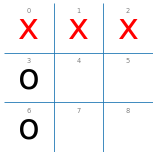

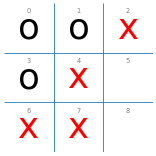


Human input position: X; opponent: random_player; seed: 20261108
Ply | Symbol | Controller | Cell | Board after move
  1 |      X | scripted input  |    0 | x.. / ... / ...
  2 |      O | random_player   |    3 | x.. / o.. / ...
  3 |      X | scripted input  |    1 | xx. / o.. / ...
  4 |      O | random_player   |    6 | xx. / o.. / o..
  5 |      X | scripted input  |    2 | xxx / o.. / o..
Final result: X wins; counts={'x': 1, 'o': 0, 'd': 0}

Human input position: O; opponent: random_player; seed: 20261109
Ply | Symbol | Controller | Cell | Board after move
  1 |      X | random_player   |    7 | ... / ... / .x.
  2 |      O | scripted input  |    0 | o.. / ... / .x.
  3 |      X | random_player   |    2 | o.x / ... / .x.
  4 |      O | scripted input  |    1 | oox / ... / .x.
  5 |      X | random_player   |    4 | oox / .x. / .x.
  6 |      O | scripted input  |    3 | oox / ox. / .x.
  7 |      X | random_player   |    6 | oox / ox. / xx.
Final result: X wins; counts={'x': 1, 

In [7]:
import numpy as np
from contextlib import redirect_stdout
from io import StringIO
from unittest.mock import patch

base_interactive_player = interactive_player
base_random_player = random_player

def run_recorded_game(human_side, seed):
    log = []

    def scripted_human(board, player=None):
        available = actions(board)
        move = available[0]
        rendered = []
        with patch.dict(base_interactive_player.__globals__, {
            'show_board': lambda state, **kwargs: rendered.append(tuple(state)),
            'clear_output': lambda **kwargs: None,
        }):
            with patch('builtins.input', side_effect=[str(move)]):
                actual_move = base_interactive_player(board, player)
        assert actual_move == move and rendered == [tuple(board)]
        log.append((player, 'scripted input', actual_move, tuple(result(board, player, actual_move))))
        return actual_move

    def recorded_random(board, player=None):
        move = base_random_player(board, player)
        log.append((player, 'random_player', move, tuple(result(board, player, move))))
        return move

    np.random.seed(seed)
    transcript = StringIO()
    with patch.dict(play_interactively.__globals__, {
        'interactive_player': scripted_human,
        'random_player': recorded_random,
    }), redirect_stdout(transcript):
        outcome = play_interactively(human_side)

    assert outcome is not None and sum(outcome.values()) == 1
    final_board = list(log[-1][3])
    assert terminal(final_board)
    return log, outcome, final_board

recorded_games = {}
for side, seed in (('x', 20261108), ('o', 20261109)):
    recorded_games[side] = run_recorded_game(side, seed)
    log, outcome, final_board = recorded_games[side]
    print(f'\nHuman input position: {side.upper()}; opponent: random_player; seed: {seed}')
    print('Ply | Symbol | Controller | Cell | Board after move')
    for ply, (player, controller, move, state) in enumerate(log, start=1):
        cells = ''.join(cell if cell != ' ' else '.' for cell in state)
        board_text = f'{cells[:3]} / {cells[3:6]} / {cells[6:]}'
        print(f'{ply:>3} | {player.upper():>6} | {controller:<15} | {move:>4} | {board_text}')
    winner = check_board(final_board)
    result_text = {'x': 'X wins', 'o': 'O wins', 'd': 'Draw'}[winner]
    print(f'Final result: {result_text}; counts={outcome}')